<div style="background:#0A005A;border-radius:18px;padding:28px 32px;color:#fff;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif">

<div style="margin-top:22px"><span style="background:#613EFF;color:#fff;padding:5px 12px;border-radius:999px;font-size:.8em;font-weight:700;letter-spacing:.06em">TUTORIAL · NOTEBOOK</span>
<span style="color:#C9C2FF;font-size:.85em;margin-left:8px">Engenharia de Dados · Nível 4 · Ingestão, orquestração e transformação</span></div>
<h1 style="color:#fff;margin:14px 0 8px;font-size:2.1em;line-height:1.15">Prática: coletar dados de uma API com Python</h1>
<p style="color:#E4E0FF;margin:0 0 12px;font-size:1.05em">Busque no PNCP as dispensas de licitação do Ministério da Justiça publicadas em junho de 2026: 61 registros em 7 páginas.</p>
<span style="display:inline-block;background:rgba(255,255,255,.12);color:#fff;padding:5px 12px;border-radius:999px;margin:4px 6px 0 0;font-size:.85em">⏱ cerca de 30 minutos</span><span style="display:inline-block;background:rgba(255,255,255,.12);color:#fff;padding:5px 12px;border-radius:999px;margin:4px 6px 0 0;font-size:.85em">🐍 Python 3.10+</span><span style="display:inline-block;background:rgba(255,255,255,.12);color:#fff;padding:5px 12px;border-radius:999px;margin:4px 6px 0 0;font-size:.85em">🌐 precisa de internet</span><span style="display:inline-block;background:rgba(255,255,255,.12);color:#fff;padding:5px 12px;border-radius:999px;margin:4px 6px 0 0;font-size:.85em">🔓 API aberta, sem senha</span>
</div>

## O que você vai construir

Uma coleta que pede os dados ao **Portal Nacional de Contratações Públicas (PNCP)**, percorre todas as páginas, espera e tenta de novo quando a API pede calma, falha de forma clara quando algo dá errado e salva o resultado em `pncp_dispensas_2026_06.json`. Esse arquivo é a entrada do próximo notebook.

<table style="border-collapse:collapse;width:100%;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><thead><tr style="background:#F2F1F6"><th style="width:56px"></th><th style="text-align:left;padding:8px 10px;width:36px">#</th><th style="text-align:left;padding:8px 10px">Passo</th><th style="text-align:left;padding:8px 10px">O que você vai ver</th></tr></thead><tbody><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">1</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Fazer um pedido</td><td style="padding:8px 10px;color:#444;text-align:left">a resposta JSON e os campos de controle</td></tr><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">2</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Olhar um registro</td><td style="padding:8px 10px;color:#444;text-align:left">chave, objetos internos e campos vazios</td></tr><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">3</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Percorrer as páginas</td><td style="padding:8px 10px;color:#444;text-align:left">laço com nova tentativa e espera</td></tr><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">4</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Provocar falhas</td><td style="padding:8px 10px;color:#444;text-align:left">tempo esgotado e erro definitivo</td></tr><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">5</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Conferir e salvar</td><td style="padding:8px 10px;color:#444;text-align:left">quantidade, duplicatas e arquivo JSON</td></tr><tr><td style="padding:8px 10px;text-align:center"></td><td style="padding:8px 10px;color:#BE006E;font-weight:700;text-align:left">6</td><td style="padding:8px 10px;color:#0A005A;font-weight:700;text-align:left">Comparar com o repositório</td><td style="padding:8px 10px;color:#444;text-align:left">as mesmas ideias no cliente do PNCP</td></tr></tbody></table>

## Como usar este notebook

Execute as células **em ordem**, de cima para baixo: clique na célula e aperte <kbd>Shift</kbd> + <kbd>Enter</kbd>. Cada passo tem uma explicação curta, o código e um quadro com o **resultado esperado** para você comparar.

<div style="border-left:5px solid #613EFF;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#613EFF">💡 Quadros roxos</b><br>explicam um conceito.</div>
<div style="border-left:5px solid #F9006F;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#F9006F">⚠️ Quadros rosa</b><br>avisam de algo que costuma dar errado.</div>
<div style="border-left:5px solid #0A005A;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#0A005A">📂 Quadros azul-marinho</b><br>mostram onde a mesma ideia aparece no repositório <code>data-application-gov-hub</code>.</div>

**Onde rodar.** Qualquer uma destas opções serve:

| Opção | Como |
|---|---|
| JupyterLab na sua máquina | `pip install jupyterlab` e depois `jupyter lab` na pasta do arquivo |
| VS Code | Abra o `.ipynb` com a extensão **Jupyter** e escolha um Python 3.10 ou mais novo |
| Jupyter da aplicação | Com o `data-application-gov-hub` no ar, coloque o arquivo na pasta `notebooks/` e abra `http://localhost:8888` |

##  Preparação

Instale o cliente HTTP `httpx` e carregue duas funções de apoio, `mostrar` e `conferir`, que desenham os quadros de conferência ao longo do notebook.

In [ ]:
%pip install -q httpx

In [ ]:
from IPython.display import HTML, display


def mostrar(tipo, titulo, detalhe=""):
    """Mostra um quadro colorido com o resultado de uma conferência."""
    cor, simbolo = {"ok": ("#613EFF", "✅"), "erro": ("#F9006F", "❌"), "info": ("#0A005A", "ℹ️")}[tipo]
    display(HTML(
        f'<div style="border-left:5px solid {cor};background:#F2F1F6;padding:10px 14px;'
        f'border-radius:8px;margin:6px 0;color:#202020"><b style="color:{cor}">{simbolo} {titulo}</b>'
        + (f"<br>{detalhe}" if detalhe else "") + "</div>"))


def conferir(condicao, certo, errado):
    """Mostra um quadro de acerto ou de erro, conforme a condição."""
    mostrar("ok" if condicao else "erro", certo if condicao else errado)


mostrar("ok", "Ambiente pronto", "Pode seguir para o passo 1.")

##  Passo 1 de 6 · Fazer um pedido e ler a resposta

Um pedido a uma API REST é um endereço com parâmetros. Aqui, os parâmetros recortam o período, a modalidade e o órgão.

<div style="border-left:5px solid #613EFF;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#613EFF">💡 Por que timeout=60?</b><br>A API do PNCP pode levar mais de 10 segundos para responder. Sem o parâmetro, o <code>httpx</code> desiste em 5 segundos e a célula falha com <code>ReadTimeout</code>.</div>

In [ ]:
import httpx

URL = "https://pncp.gov.br/api/consulta/v1/contratacoes/publicacao"
FILTRO = {
    "dataInicial": "20260601",
    "dataFinal": "20260630",
    "codigoModalidadeContratacao": 8,   # 8 = dispensa de licitação
    "cnpj": "00394494000136",           # Ministério da Justiça e Segurança Pública
}

resposta = httpx.get(URL, params={**FILTRO, "pagina": 1}, timeout=60)
print(resposta.status_code)
corpo = resposta.json()
print({chave: valor for chave, valor in corpo.items() if chave != "data"})
print(len(corpo["data"]))

<details>
<summary><b>✔️ Resultado esperado</b> (clique para abrir)</summary>

```text
200
{'totalRegistros': 61, 'totalPaginas': 7, 'numeroPagina': 1, 'paginasRestantes': 6, 'empty': False}
10
```

</details>

A resposta tem duas partes: `data`, com os registros desta página (10), e os **campos de controle**, que contam quantos registros e páginas existem no total.

<div style="border-left:5px solid #BE006E;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#BE006E">🧭 Números um pouco diferentes?</b><br>Se o órgão publicar ou corrigir registros depois desta aula, os totais mudam. O raciocínio é o mesmo.</div>

In [ ]:
conferir(resposta.status_code == 200, "A API respondeu (200)", f"A API respondeu {resposta.status_code}: confira a internet e rode de novo")

##  Passo 2 de 6 · Olhar um registro

Antes de coletar tudo, entenda o formato de **um** registro.

In [ ]:
primeiro = corpo["data"][0]
print(primeiro["numeroControlePNCP"], primeiro["valorTotalEstimado"])
print(primeiro["orgaoEntidade"]["razaoSocial"])
print(primeiro["unidadeOrgao"]["ufSigla"], primeiro["unidadeOrgao"]["nomeUnidade"])
print(sorted(primeiro)[:10], "...", len(primeiro), "campos")

<details>
<summary><b>✔️ Resultado esperado</b> (clique para abrir)</summary>

```text
00394494000136-1-000543/2026 16505.36
MINISTERIO DA JUSTICA E SEGURANCA PUBLICA
DF PENITENCIÁRIA FEDERAL EM BRASILIA
['amparoLegal', 'anoCompra', 'dataAberturaProposta', ..., 'fontesOrcamentarias'] ... 35 campos
```

</details>

Três observações que valem para qualquer fonte:

| O quê | Neste registro | Por que importa |
|---|---|---|
| **Chave** | `numeroControlePNCP` | É por ela que o banco vai evitar duplicatas |
| **Objetos internos** | `orgaoEntidade`, `unidadeOrgao` | Na hora de gravar, viram colunas separadas |
| **Campos vazios** | `valorTotalHomologado` é `None` quando a compra ainda não foi homologada | Reaparece na prática de dbt como `NaN` |

In [ ]:
sem_homologacao = sum(1 for r in corpo["data"] if r["valorTotalHomologado"] is None)
mostrar("info", f"{sem_homologacao} de {len(corpo['data'])} registros desta página sem valor homologado",
        "Guarde isso: campos vazios precisam de uma regra na transformação.")

##  Passo 3 de 6 · Percorrer todas as páginas, com nova tentativa

A coleta pede a página 1, lê `totalPaginas` e continua até a última. Cada pedido passa por uma função que separa dois tipos de problema:

| Tipo | Exemplos | O que fazer |
|---|---|---|
| **Temporário** | tempo esgotado, `429 Too Many Requests`, erros `5xx` | Esperar e tentar de novo |
| **Definitivo** | `400`, `401`, `404`, `422` | Parar: o pedido está errado e repetir não muda a resposta |

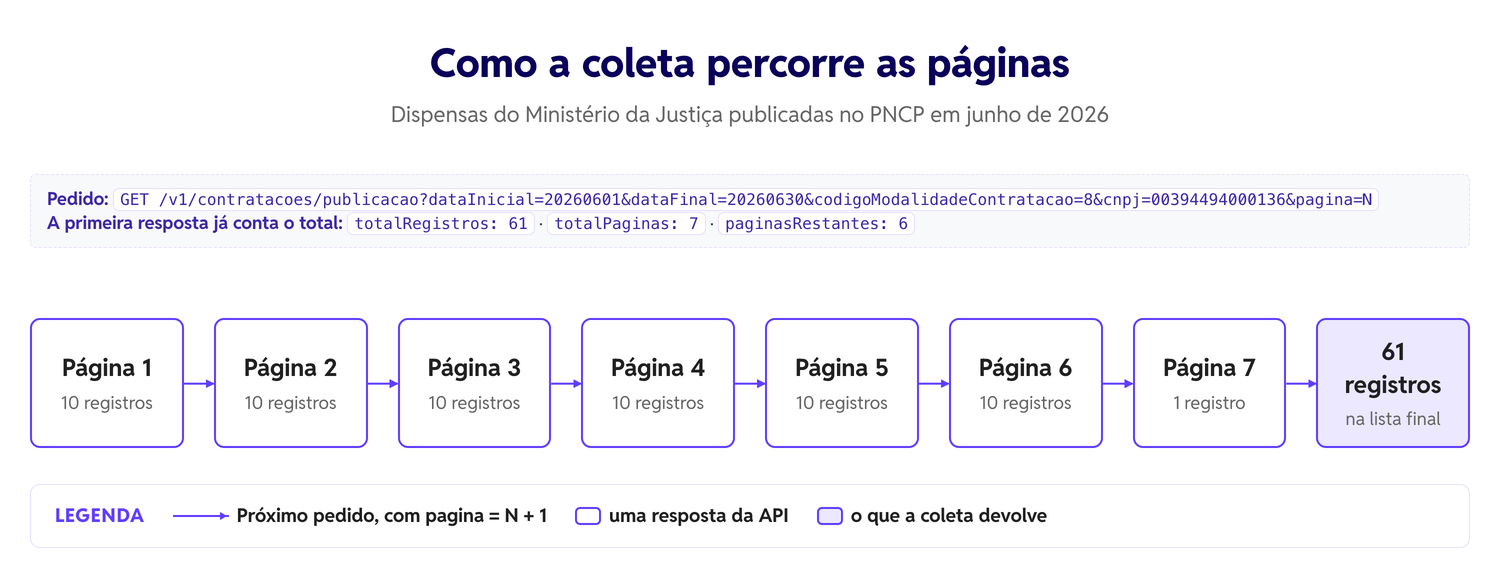

In [ ]:
import time

TEMPORARIOS = {429, 500, 502, 503, 504}


def pedir_pagina(cliente, filtro, pagina, tentativas=4):
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = cliente.get(URL, params={**filtro, "pagina": pagina})
        except httpx.TimeoutException:
            motivo = "tempo esgotado"
        else:
            if resposta.status_code not in TEMPORARIOS:
                resposta.raise_for_status()   # 4xx: erro definitivo, sobe na hora
                return resposta.json()
            motivo = f"HTTP {resposta.status_code}"
        if tentativa == tentativas:
            raise RuntimeError(f"página {pagina}: {motivo} após {tentativas} tentativas")
        espera = 5 * tentativa
        print(f"página {pagina}: {motivo}; nova tentativa em {espera}s")
        time.sleep(espera)


def coletar(filtro, timeout=60):
    registros = []
    pagina, total_paginas = 1, 1
    with httpx.Client(timeout=timeout) as cliente:
        while pagina <= total_paginas:
            corpo = pedir_pagina(cliente, filtro, pagina)
            total_paginas = corpo["totalPaginas"]
            registros.extend(corpo["data"])
            print(f"página {pagina}/{total_paginas}: {len(corpo['data'])} registros")
            pagina += 1
            time.sleep(1)   # gentileza com a API: um pedido por segundo
    return registros


registros = coletar(FILTRO)
print(len(registros))

<details>
<summary><b>✔️ Resultado esperado (a linha de nova tentativa só aparece se a API pedir calma)</b> (clique para abrir)</summary>

```text
página 1/7: 10 registros
página 2/7: 10 registros
página 3/7: 10 registros
página 4/7: 10 registros
página 5: HTTP 429; nova tentativa em 5s
página 5/7: 10 registros
página 6/7: 10 registros
página 7/7: 1 registros
61
```

</details>

<div style="border-left:5px solid #613EFF;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#613EFF">💡 De onde vem o critério de parada</b><br>Da própria API: <code>totalPaginas</code>. Não use “a página veio com menos de 10” como regra universal. Cada fonte tem o seu critério: leia a documentação e confira na primeira resposta.</div>

##  Passo 4 de 6 · Provocar as duas falhas

Uma coleta bem feita falha **de forma visível**. Primeiro, um tempo esgotado: um centésimo de segundo é impossível de cumprir.

In [ ]:
try:
    with httpx.Client(timeout=0.01) as cliente:
        pedir_pagina(cliente, FILTRO, 1, tentativas=2)
except RuntimeError as erro:
    mostrar("erro", "A coleta falhou, como esperado", str(erro))

<details>
<summary><b>✔️ Resultado esperado</b> (clique para abrir)</summary>

```text
página 1: tempo esgotado; nova tentativa em 5s
❌ A coleta falhou, como esperado
página 1: tempo esgotado após 2 tentativas
```

</details>

Agora um erro **definitivo**: a data no formato errado.

In [ ]:
try:
    with httpx.Client(timeout=60) as cliente:
        pedir_pagina(cliente, {**FILTRO, "dataInicial": "2026-06-01"}, 1)
except httpx.HTTPStatusError as erro:
    mostrar("erro", f"Erro definitivo: HTTP {erro.response.status_code}", "Subiu na primeira tentativa, sem espera.")

<details>
<summary><b>✔️ Resultado esperado</b> (clique para abrir)</summary>

```text
❌ Erro definitivo: HTTP 422
Subiu na primeira tentativa, sem espera.
```

</details>

O PNCP responde `422 Unprocessable Entity`: entendeu o pedido, mas o parâmetro é inválido. Repetir um pedido errado só gasta o limite da API.

##  Passo 5 de 6 · Conferir e salvar

Antes de entregar a coleta para a próxima etapa, confira duas coisas: **veio tudo?** e **nada veio repetido?**

In [ ]:
import json

ids = {r["numeroControlePNCP"] for r in registros}
conferir(len(registros) == corpo["totalRegistros"],
         f"Veio tudo: {len(registros)} de {corpo['totalRegistros']} registros",
         f"Faltam registros: {len(registros)} de {corpo['totalRegistros']}")
conferir(len(ids) == len(registros),
         "Nenhum registro repetido",
         f"Há {len(registros) - len(ids)} registros repetidos")

with open("pncp_dispensas_2026_06.json", "w", encoding="utf-8") as arquivo:
    json.dump(registros, arquivo, ensure_ascii=False)
mostrar("info", "Arquivo salvo: pncp_dispensas_2026_06.json", "Ele fica na mesma pasta deste notebook e é a entrada do próximo.")

##  Passo 6 de 6 · Encontrar as mesmas ideias no repositório

Abra [`plugins/cliente_pncp.py`](https://github.com/GovHub-br/data-application-gov-hub/blob/main/airflow_lappis/plugins/cliente_pncp.py) e [`plugins/cliente_base.py`](https://github.com/GovHub-br/data-application-gov-hub/blob/main/airflow_lappis/plugins/cliente_base.py) no `data-application-gov-hub` e compare:

| Neste notebook | No repositório |
|---|---|
| `httpx.Client(timeout=60)` | `ClienteBase` cria um `httpx.Client` com `DEFAULT_TIMEOUT = 10` |
| `pedir_pagina`, com tentativas e espera | [`helpers/safe_request.py`](https://github.com/GovHub-br/data-application-gov-hub/blob/main/airflow_lappis/helpers/safe_request.py): até 3 tentativas, espera crescente |
| Laço até `totalPaginas` | `ClientePNCP.get_contratacoes_publicacao_paginado` |
| `conferir(...)` da quantidade | Fica a cargo da DAG, na prática do Airflow |

<div style="border-left:5px solid #F9006F;background:#F2F1F6;padding:12px 16px;border-radius:10px;margin:10px 0;color:#202020;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif"><b style="color:#F9006F">⚠️ Uma diferença importante</b><br>Quando as tentativas acabam, o <code>safe_request</code> não levanta erro: devolve o status 503, e o <code>ClientePNCP</code> devolve uma lista vazia. O método paginado entende isso como “acabaram as páginas”. Resultado: uma coleta interrompida na página 2 termina com sucesso e com 10 registros em vez de 61. Na prática do Airflow você vê isso acontecer e protege a DAG.</div>

##  Desafios

Use as funções que você escreveu. As respostas estão escondidas abaixo de cada desafio.

**1.** Quantas contratações há em cada UF? Mostre da maior para a menor.

<details>
<summary><b>✔️ Ver uma resposta</b> (clique para abrir)</summary>

```text
from collections import Counter
for uf, quantidade in Counter(r["unidadeOrgao"]["ufSigla"] for r in registros).most_common():
    print(uf, quantidade)
```

</details>

**2.** Qual o valor total estimado e quanto dele já foi homologado?

<details>
<summary><b>✔️ Ver uma resposta</b> (clique para abrir)</summary>

```text
estimado = sum(r["valorTotalEstimado"] for r in registros)
homologado = sum(r["valorTotalHomologado"] or 0 for r in registros)
print(f"R$ {estimado:,.2f} estimado, R$ {homologado:,.2f} homologado")
```

</details>

**3.** Colete os **pregões eletrônicos** (modalidade `6`) do mesmo órgão e período. Quantas páginas foram?

<details>
<summary><b>✔️ Ver uma resposta</b> (clique para abrir)</summary>

```text
pregoes = coletar({**FILTRO, "codigoModalidadeContratacao": 6})
print(len(pregoes))
```

</details>

In [ ]:
# Escreva aqui as suas respostas

## O que você aprendeu

- Uma coleta é um laço de pedidos guiado pelo que a própria API informa.
- Tempo limite, nova tentativa com espera e separação entre erro temporário e definitivo **fazem parte** da coleta.
- Conferir quantidade e chave antes de seguir evita que uma carga parcial passe como completa.

<div style="background:#F2F1F6;border-radius:16px;padding:22px 26px;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif;border:2px solid #613EFF">
<div style="color:#BE006E;font-weight:700;font-size:.8em;letter-spacing:.06em">PRÓXIMO PASSO</div>
<div style="color:#0A005A;font-size:1.3em;font-weight:800;margin:6px 0">Prática: gravar a coleta em bancos de dados</div>
<div style="color:#333">Baixe o notebook <code>engenharia-ingestao-bancos.ipynb</code> na mesma aula da trilha, ou leia a versão em texto em
<a href="https://gov-hub.io/capacitacao/doc.html?trilha=engenharia-de-dados&path=docs/tutoriais/engenharia-coleta-python.md">gov-hub.io/capacitacao</a>.</div>
</div>

<p style="text-align:center;color:#666;font-size:.85em;margin-top:18px;font-family:'Reddit Sans', 'Open Sans', system-ui, sans-serif">Capacitação Gov Hub · Trilha de Engenharia de Dados · material aberto, feito para ser executado na sua máquina.</p>